In [12]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2
import matplotlib.pyplot as plt

In [13]:
rng = np.random.default_rng(seed=42)
def simulate_trial(n_per_arm, rng):
    x_i = np.repeat([0, 1], n_per_arm)
    z_i = rng.binomial(n=1, p=0.5, size=2 * n_per_arm)
    n_i = np.log(7/13) + np.log(1.6)*x_i + np.log(39/7)*z_i
    p_i = 1 / (1+np.exp(-n_i))
    Y_i = rng.binomial(1, p_i)
    return x_i, z_i, Y_i


    

In [14]:
x,z,y = simulate_trial(100, rng)
df = pd.DataFrame({"x":x , "z":z, "y":y})
df.groupby(["x", "z"])["y"].mean()

x  z
0  0    0.396226
   1    0.787234
1  0    0.470588
   1    0.877551
Name: y, dtype: float64

In [15]:
fit_full = smf.glm("y ~ z + x", data=df, family=sm.families.Binomial()).fit()
fit_full.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                      y   No. Observations:                  200
Model:                            GLM   Df Residuals:                      197
Model Family:                Binomial   Df Model:                            2
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -113.53
Date:                Tue, 24 Nov 2026   Deviance:                       227.06
Time:                        20:43:26   Pearson chi2:                     199.
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1712
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.4817      0.257     -1.873      0.061      -0.986       0.022
z              1.8898      0.340      5.560      0.000       1.224       2.556
x              0.4239      0.323      1.312      0.190      -0.209       1.057
==============================================================================
"""

In [16]:
fit_null = smf.glm("y ~ z", data=df, family=sm.families.Binomial()).fit()
lrt_stat = fit_null.deviance - fit_full.deviance
p_val = chi2.sf(lrt_stat, df = 1)
reject_h0 = p_val < 0.05

print(f"LRT stat: {lrt_stat:.4f}, p-value: {p_val:.4f}, Reject H0: {reject_h0}")

LRT stat: 1.7336, p-value: 0.1880, Reject H0: False


In [17]:
rng2 = np.random.default_rng(42)
def one_trial(n_per_arm, rng):
    x, z, y = simulate_trial(n_per_arm, rng)
    df = df = pd.DataFrame({"x":x , "z":z, "y":y})
    fit_full_adjusted = smf.glm("y ~ z + x", data=df, family=sm.families.Binomial()).fit()
    fit_null_adjusted = smf.glm("y ~ z", data=df, family=sm.families.Binomial()).fit()
    fit_full_unadjusted = smf.glm("y ~ x", data=df, family=sm.families.Binomial()).fit()
    fit_null_unadjusted = smf.glm("y ~ 1", data=df, family=sm.families.Binomial()).fit()
    lrt_stat_adjusted = fit_null_adjusted.deviance - fit_full_adjusted.deviance
    lrt_stat_unadjusted = fit_null_unadjusted.deviance - fit_full_unadjusted.deviance
    reject_adj = lrt_stat_adjusted > chi2.ppf(0.95, df = 1)
    reject_unadj = lrt_stat_unadjusted > chi2.ppf(0.95, df = 1)
    return (reject_adj, reject_unadj)


    

In [18]:
one_trial(200, rng2)

(np.True_, np.True_)

In [19]:
rng = np.random.default_rng(42)
M = 1000
n_grid = np.arange(50, 451, 25)

rows = []
for n in n_grid:
    # Shape: (M, 2) array of True/False
    trials = np.array([one_trial(n, rng) for _ in range(M)])
    power_adj, power_unadj = trials.mean(axis=0)
    
    se_adj = np.sqrt(power_adj * (1 - power_adj) / M)
    se_unadj = np.sqrt(power_unadj * (1 - power_unadj) / M)
    
    rows.append({
        "n_per_arm": n,
        "n_total": 2 * n,
        "power_adj": power_adj,
        "se_adj": se_adj,
        "power_unadj": power_unadj,
        "se_unadj": se_unadj,
    })

results_df = pd.DataFrame(rows)
print(results_df)

    n_per_arm  n_total  power_adj    se_adj  power_unadj  se_unadj
0          50      100      0.216  0.013013        0.185  0.012279
1          75      150      0.262  0.013905        0.244  0.013582
2         100      200      0.328  0.014846        0.288  0.014320
3         125      250      0.402  0.015505        0.328  0.014846
4         150      300      0.442  0.015705        0.391  0.015431
5         175      350      0.511  0.015808        0.455  0.015747
6         200      400      0.557  0.015708        0.476  0.015793
7         225      450      0.617  0.015372        0.541  0.015758
8         250      500      0.663  0.014948        0.596  0.015517
9         275      550      0.685  0.014689        0.620  0.015349
10        300      600      0.729  0.014056        0.640  0.015179
11        325      650      0.756  0.013582        0.682  0.014727
12        350      700      0.800  0.012649        0.726  0.014104
13        375      750      0.806  0.012505        0.734  0.01

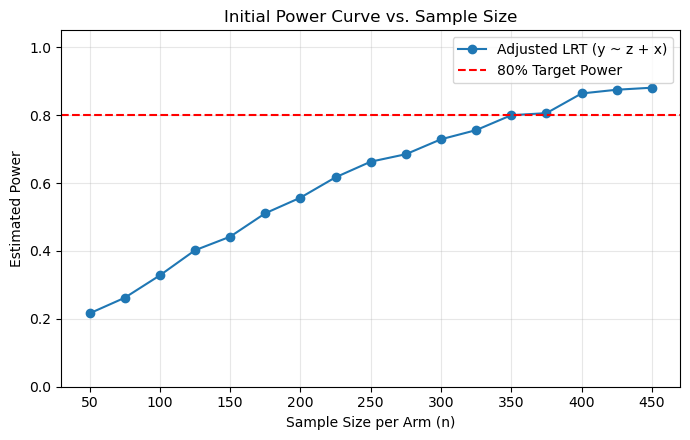

In [20]:

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(results_df["n_per_arm"], results_df["power_adj"], marker="o", label="Adjusted LRT (y ~ z + x)")
ax.axhline(0.80, color="red", linestyle="--", label="80% Target Power")

ax.set_xlabel("Sample Size per Arm (n)")
ax.set_ylabel("Estimated Power")
ax.set_title("Initial Power Curve vs. Sample Size")
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

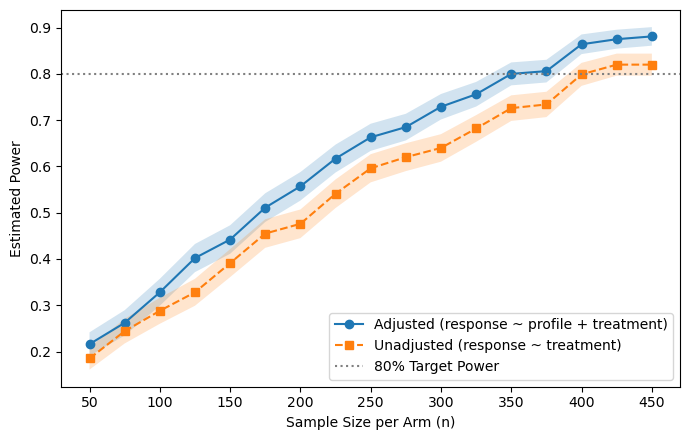

In [21]:


fig, ax = plt.subplots(figsize=(7, 4.5))

# Adjusted power curve + 95% Monte Carlo band
ax.plot(results_df["n_per_arm"], results_df["power_adj"], "o-", label="Adjusted (response ~ profile + treatment)")
ax.fill_between(
    results_df["n_per_arm"],
    results_df["power_adj"] - 1.96 * results_df["se_adj"],
    results_df["power_adj"] + 1.96 * results_df["se_adj"],
    alpha=0.2,
)

# Unadjusted power curve + 95% Monte Carlo band
ax.plot(results_df["n_per_arm"], results_df["power_unadj"], "s--", label="Unadjusted (response ~ treatment)")
ax.fill_between(
    results_df["n_per_arm"],
    results_df["power_unadj"] - 1.96 * results_df["se_unadj"],
    results_df["power_unadj"] + 1.96 * results_df["se_unadj"],
    alpha=0.2,
)

ax.axhline(0.80, color="gray", linestyle=":", label="80% Target Power")
ax.set_xlabel("Sample Size per Arm (n)")
ax.set_ylabel("Estimated Power")
ax.legend()
plt.tight_layout()
plt.show()

In [22]:
rng = np.random.default_rng(42)
large_n = 200000
x1, z1, y1 = simulate_trial(large_n, rng)
df2 = pd.DataFrame({'x':x1, 'z':z1, 'y':y1})

fit_1 = smf.glm("y ~ z + x", data=df2, family=sm.families.Binomial()).fit()
fit_2 = smf.glm("y ~ x", data=df2, family=sm.families.Binomial()).fit()

print("Adjusted Beta_1 : " + str(fit_1.params['x']))
print("Unadjusted Beta_1 : " + str(fit_2.params['x']))

Adjusted Beta_1 : 0.4780434681549092
Unadjusted Beta_1 : 0.4035739690216852
